In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
spam = pd.read_csv(r"C:\Users\Bibhu\Downloads\spam (1).csv",encoding ='ISO-8859-1')
spam

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [4]:
spam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [3]:
spam.isnull().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

In [4]:
spam.drop(['Unnamed: 2','Unnamed: 3','Unnamed: 4'],axis=1,inplace=True)
spam.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
spam.columns=['labels','messages']
spam.head()

,labels,messages
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [6]:
spam['b_lebel']=spam['labels'].map({'ham':0,
                                   'spam':1})
spam

,labels,messages,b_lebel
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,1
5568,ham,Will Ì_ b going to esplanade fr home?,0
5569,ham,"Pity, * was in mood for that. So...any other s...",0
5570,ham,The guy did some bitching but I acted like i'd...,0


In [7]:
ip=spam.messages
op=spam["b_lebel"].values

In [8]:
ip.head()

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: messages, dtype: object

In [9]:
# Train Test Split

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
x_train,x_test,y_train,y_test=train_test_split(ip,op,test_size=0.35)

In [12]:
print(x_train.shape)
print(x_test.shape)  

(3621,)
(1951,)


In [13]:
# it converts text into numeric vector based in word importance 
from sklearn.feature_extraction.text import  TfidfVectorizer
tfidf=TfidfVectorizer()
x_train=tfidf.fit_transform(x_train)
x_test=tfidf.transform(x_test)

In [14]:
# here we will use multinomial naive baise
from sklearn.naive_bayes import MultinomialNB
algo= MultinomialNB()
algo.fit(x_train,y_train)

MultinomialNB()

In [15]:
print('Training Score:',algo.score(x_train,y_train))
print('Train Score:',algo.score(x_test,y_test))

Training Score: 0.9696216514774924
Train Score: 0.946694003075346


In [16]:
pred=algo.predict(x_test)
pred

array([0, 1, 0, ..., 0, 0, 0], dtype=int64)

In [17]:
# we are using multinomial category in naive bayse so we find accuracy_score, recall_score, f1_score, precision_score
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score

acc = accuracy_score(y_test, pred)
recall = recall_score(y_test, pred)
f1 = f1_score(y_test, pred)
precision = precision_score(y_test, pred)

print("Accuracy:", acc)
print("Recall score:", recall)
print("F1 score:", f1)
print("Precision score:", precision)

Accuracy: 0.946694003075346
Recall score: 0.6338028169014085
F1 score: 0.7758620689655172
Precision score: 1.0


# word cloud

In [18]:
from wordcloud import WordCloud

# install word cloud
!pip3 install WordCloud

In [19]:
def visualize(lebel):
    words = ''
    for msg in spam[spam['labels'] == lebel]['messages']:
        msg = str(msg).lower()
        words += msg + ' '  # Added space between words
        
    wordCloud = WordCloud(width=600, height=400).generate(words)  # Fixed typo 'genarate'
    plt.imshow(wordCloud)
    plt.axis('off')
    plt.show()

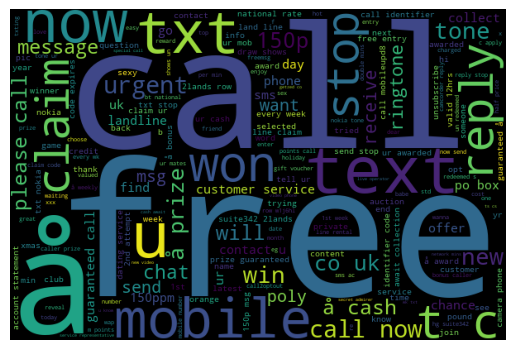

In [20]:
visualize('spam')

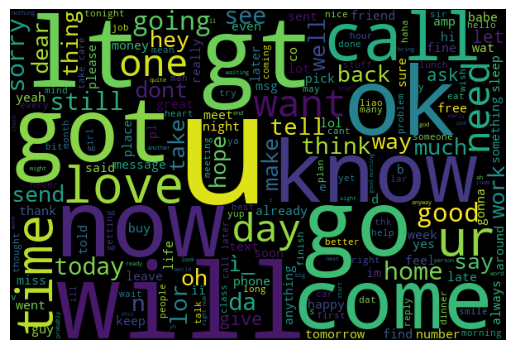

In [21]:
visualize('ham')

# Fetch_20 News Group:

In [22]:
from sklearn.datasets import fetch_20newsgroups

In [23]:
news=fetch_20newsgroups()

In [24]:
print(news.data[10])

From: irwin@cmptrc.lonestar.org (Irwin Arnstein)
Subject: Re: Recommendation on Duc
Summary: What's it worth?
Distribution: usa
Expires: Sat, 1 May 1993 05:00:00 GMT
Organization: CompuTrac Inc., Richardson TX
Keywords: Ducati, GTS, How much? 
Lines: 13

I have a line on a Ducati 900GTS 1978 model with 17k on the clock.  Runs
very well, paint is the bronze/brown/orange faded out, leaks a bit of oil
and pops out of 1st with hard accel.  The shop will fix trans and oil 
leak.  They sold the bike to the 1 and only owner.  They want $3495, and
I am thinking more like $3K.  Any opinions out there?  Please email me.
Thanks.  It would be a nice stable mate to the Beemer.  Then I'll get
a jap bike and call myself Axis Motors!

-- 
-----------------------------------------------------------------------
"Tuba" (Irwin)      "I honk therefore I am"     CompuTrac-Richardson,Tx
irwin@cmptrc.lonestar.org    DoD #0826          (R75/6)
-------------------------------------------------------------------

In [25]:
set(news.target)

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19}

In [26]:
news.target_names

['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

In [27]:
news_train=fetch_20newsgroups(subset='train')
news_test=fetch_20newsgroups(subset='test')

In [28]:
print(news_train.data[10])

From: irwin@cmptrc.lonestar.org (Irwin Arnstein)
Subject: Re: Recommendation on Duc
Summary: What's it worth?
Distribution: usa
Expires: Sat, 1 May 1993 05:00:00 GMT
Organization: CompuTrac Inc., Richardson TX
Keywords: Ducati, GTS, How much? 
Lines: 13

I have a line on a Ducati 900GTS 1978 model with 17k on the clock.  Runs
very well, paint is the bronze/brown/orange faded out, leaks a bit of oil
and pops out of 1st with hard accel.  The shop will fix trans and oil 
leak.  They sold the bike to the 1 and only owner.  They want $3495, and
I am thinking more like $3K.  Any opinions out there?  Please email me.
Thanks.  It would be a nice stable mate to the Beemer.  Then I'll get
a jap bike and call myself Axis Motors!

-- 
-----------------------------------------------------------------------
"Tuba" (Irwin)      "I honk therefore I am"     CompuTrac-Richardson,Tx
irwin@cmptrc.lonestar.org    DoD #0826          (R75/6)
-------------------------------------------------------------------

In [29]:
print(news_test.data[6])

From: PETCH@gvg47.gvg.tek.com (Chuck)
Subject: Daily Verse
Lines: 3

Dishonest money dwindles away, but he who gathers money little by little makes
it grow. 
Proverbs 13:11



In [30]:
print(len(news_train.data))

11314


In [31]:
print(len(news_test.data))

7532


In [32]:
11314+7532

18846

In [33]:
# total number of sample present in dataset
a=fetch_20newsgroups(subset='all')
print(len(a.data))

18846


In [34]:
# tfidfTransformer :- it calculate important scores from existion count

In [41]:
from sklearn.feature_extraction.text import TfidfTransformer

In [42]:
 from sklearn.feature_extraction.text import TfidfVectorizer,TfidfTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB

In [43]:
model = Pipeline([
    ('vector', TfidfVectorizer()),
    ('tfidf',TfidfTransformer()),
    ('algo', MultinomialNB())
])



In [44]:
model.fit(news_train.data, news_train.target)

Pipeline(steps=[('vector', TfidfVectorizer()), ('tfidf', TfidfTransformer()),
                ('algo', MultinomialNB())])

In [39]:
def predict_category(s,train=news_train,model=model):
    pred=model.predict([s])
    return train.target_names[pred[0]]

In [52]:
predict_category("Modi is our prime minister")

'talk.politics.mideast'

In [47]:
def predict_category(s, train=news_train, model=model):
    pred = model.predict([s])
    return train.target_names[pred[0]]

# 4. Test it immediately
print(predict_category("Drapadi Murmu is our president"))

talk.politics.misc
